### Importando as Bibliotecas e Funções

In [1]:
!pip install pyTelegramBotAPI

In [2]:
import pandas as pd
import numpy as np

import telebot
import time

from datetime import datetime
import pytz

import warnings
warnings.filterwarnings('ignore')

def drop_reset_index(df):
    df = df.dropna()
    df = df.reset_index(drop=True)
    df.index += 1
    return df

def plot_profit_acu(dataframe, title_text):
    dataframe['Profit_acu'] = dataframe.Profit.cumsum()
    n_apostas = dataframe.shape[0]
    profit = round(dataframe.Profit_acu.tail(1).item(), 2)
    ROI = round((dataframe.Profit_acu.tail(1) / n_apostas * 100).item(), 2)
    drawdown = dataframe['Profit_acu'] - dataframe['Profit_acu'].cummax()
    drawdown_maximo = round(drawdown.min(), 2)
    winrate_medio = round((dataframe['Profit'] > 0).mean() * 100, 2)
    desvio_padrao = round(dataframe['Profit'].std(), 2)
    dataframe.Profit_acu.plot(title=title_text, xlabel='Entradas', ylabel='Stakes')
    print("Metodo:",title_text)
    print("Profit:", profit, "stakes em", n_apostas, "jogos")
    print("ROI:", ROI, "%")
    print("Drawdown Maximo Acumulado:", drawdown_maximo)
    print("Winrate Medio:", winrate_medio, "%")
    print("Desvio Padrao:", desvio_padrao)
    print("")

def ajustar_id_mercado(id_mercado, comprimento_decimal_desejado=9):
    id_mercado_str = str(id_mercado)
    partes = id_mercado_str.split('.')
    if len(partes) == 1:
        return id_mercado_str + '.' + '0' * comprimento_decimal_desejado
    parte_inteira, parte_decimal = partes
    zeros_para_adicionar = comprimento_decimal_desejado - len(parte_decimal)
    if zeros_para_adicionar > 0:
        parte_decimal += '0' * zeros_para_adicionar
    id_mercado_ajustado = parte_inteira + '.' + parte_decimal
    return id_mercado_ajustado

def remove_outliers(df, cols):
    for col in cols:
        Q1 = df[col].quantile(0.05)
        Q3 = df[col].quantile(0.95)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]
    return df

def entropy(probabilities):
    probabilities = probabilities[probabilities > 0]
    return -np.sum(probabilities * np.log2(probabilities))

### Backtesting

In [3]:
df = pd.read_csv("https://github.com/futpythontrader/YouTube/raw/main/Luke/Bases_de_Dados/Base%20de%20Dados_Betfair_Exchange.csv")
df = df[['Date','League','Home','Away','Goals_H','Goals_A',
'Odd_H_Back','Odd_H_Lay','Odd_A_Back','Odd_A_Lay','Odd_D_Back','Odd_D_Lay',
'Odd_Under25_FT_Back','Odd_Over25_FT_Back','Odd_BTTS_Yes_Back','Odd_BTTS_No_Back',
'Odd_CS_0x0_Back','Odd_CS_0x0_Lay','Odd_CS_0x1_Back','Odd_CS_0x1_Lay','Odd_CS_0x2_Back','Odd_CS_0x2_Lay','Odd_CS_0x3_Back','Odd_CS_0x3_Lay',
'Odd_CS_1x0_Back','Odd_CS_1x0_Lay','Odd_CS_1x1_Back','Odd_CS_1x1_Lay','Odd_CS_1x2_Back','Odd_CS_1x2_Lay','Odd_CS_1x3_Back','Odd_CS_1x3_Lay',
'Odd_CS_2x0_Back','Odd_CS_2x0_Lay','Odd_CS_2x1_Back','Odd_CS_2x1_Lay','Odd_CS_2x2_Back','Odd_CS_2x2_Lay','Odd_CS_2x3_Back','Odd_CS_2x3_Lay',
'Odd_CS_3x0_Back','Odd_CS_3x0_Lay','Odd_CS_3x1_Back','Odd_CS_3x1_Lay','Odd_CS_3x2_Back','Odd_CS_3x2_Lay','Odd_CS_3x3_Back','Odd_CS_3x3_Lay',
'Odd_CS_Goleada_H_Back','Odd_CS_Goleada_H_Lay','Odd_CS_Goleada_A_Back','Odd_CS_Goleada_A_Lay','Odd_CS_Goleada_D_Back','Odd_CS_Goleada_D_Lay']]
df = drop_reset_index(df)

In [4]:
odds_columns = [col for col in df.columns if 'Odd_' in col]

df_clean = remove_outliers(df, odds_columns)
df = drop_reset_index(df_clean)

cs_lay_columns = [col for col in df.columns if 'CS' in col and 'Lay' in col]
cs_lay_data = df[cs_lay_columns]
cv_cs_lay = cs_lay_data.apply(lambda x: x.std() / x.mean(), axis=1)
df['CV_CS'] = cv_cs_lay

probabilities_cs = cs_lay_data.replace(0, np.nan).apply(lambda x: 1 / x, axis=1)
entropy_cs = probabilities_cs.apply(lambda x: -np.sum(x * np.log2(x)) if x.sum() != 0 else 0, axis=1)
df['Entropy_CS'] = entropy_cs

df['Lay_0x1'] = np.where((df['Goals_H'] == 0) & (df['Goals_A'] == 1), 0, 1)
df['Profit_Lay_0x1'] = np.where((df['Lay_0x1'] == 1), 0.94/(df['Odd_CS_0x1_Lay']-1), -1)

Metodo: Lay 0 x 1
Profit: 166.82 stakes em 319 jogos
ROI: 52.29 %
Drawdown Maximo Acumulado: -26.0
Winrate Medio: 96.55 %
Desvio Padrao: 2.24



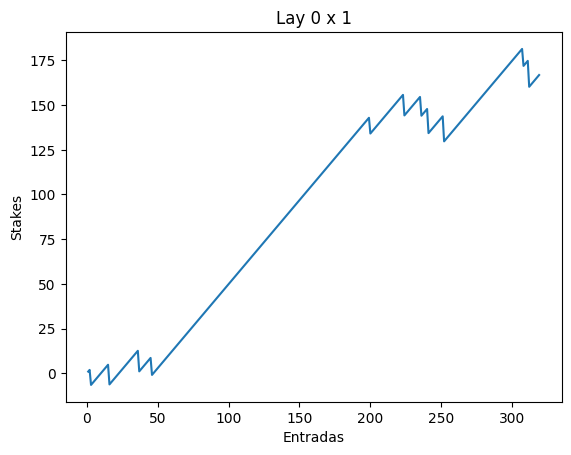

In [5]:
flt = (df.CV_CS > 2.6) & (df.Entropy_CS > 3.6)
df0 = df[flt]
df0 = drop_reset_index(df0)
df0['Profit'] = df0['Profit_Lay_0x1']
df0['Profit'] = 0.94
df0.loc[((df0['Goals_H'] == 0) & (df0['Goals_A'] == 1)), 'Profit'] = -1 * (df0['Odd_CS_0x1_Lay'] - 1)
plot_profit_acu(df0, 'Lay 0 x 1')

### Entradas

In [6]:
dia = '2024-04-27'

df = pd.read_csv(f'https://github.com/futpythontrader/YouTube/raw/main/Luke/Jogos_do_Dia/Jogos_do_Dia_Betfair_Back_Lay_{dia}.csv')

odds_columns = [col for col in df.columns if 'Odd_' in col]

df_clean = remove_outliers(df, odds_columns)
df = drop_reset_index(df_clean)

cs_lay_columns = [col for col in df.columns if 'CS' in col and 'Lay' in col]
cs_lay_data = df[cs_lay_columns]
cv_cs_lay = cs_lay_data.apply(lambda x: x.std() / x.mean(), axis=1)
df['CV_CS'] = cv_cs_lay

probabilities_cs = cs_lay_data.replace(0, np.nan).apply(lambda x: 1 / x, axis=1)
entropy_cs = probabilities_cs.apply(lambda x: -np.sum(x * np.log2(x)) if x.sum() != 0 else 0, axis=1)
df['Entropy_CS'] = entropy_cs

flt = (df.CV_CS > 2.6) & (df.Entropy_CS > 3.6)
df0 = df[flt]
df0 = drop_reset_index(df0)

df0[['Date','Time','League','Home','Away','Odd_CS_0x1_Lay']]

,Date,Time,League,Home,Away,Odd_CS_0x1_Lay
1,2024-04-27,02:00:00,South Korean K League 1,Daejeon Citizen,FC Seoul,10.5
2,2024-04-27,03:00:00,Japanese J League,C-Osaka,Yokohama FM,15.0
3,2024-04-27,04:15:00,Australian A-League Men,Newcastle Jets,Central Coast Mariners,14.5
4,2024-04-27,04:15:00,Australian A-League Men,Wellington Phoenix,Macarthur FC,28.0
5,2024-04-27,06:45:00,Australian A-League Men,Melbourne Victory,Western Sydney Wanderers,25.0
6,2024-04-27,08:00:00,German Bundesliga 2,Holstein Kiel,Kaiserslautern,25.0
7,2024-04-27,08:00:00,German Bundesliga 2,Braunschweig,Hamburger SV,13.5
8,2024-04-27,08:30:00,English League 1,Lincoln,Portsmouth,15.5
9,2024-04-27,08:30:00,English League 1,Wycombe,Charlton,14.5
10,2024-04-27,08:30:00,English League 1,Fleetwood Town,Burton Albion,16.5


In [7]:
brazil_timezone = pytz.timezone('America/Sao_Paulo')
current_time_brazil = datetime.now(brazil_timezone).strftime('%H:%M:%S')

df0['Time'] = pd.to_datetime(df0['Time']).dt.time
df0 = df0[df0['Time'] > datetime.strptime(current_time_brazil, '%H:%M:%S').time()]
df0[['Date','Time','League','Home','Away','Odd_CS_0x1_Lay']]

In [8]:
bot = telebot.TeleBot('6898155329:AAHbYxeAex4bDophrBoHj6XTN5SurIXKkyw')

mensagem_inicializacao = "Atenção! \nEntrada em Instantes!"
chat_channel = '-1002072379223'
bot.send_message(chat_channel, mensagem_inicializacao)

try:

    for a,b,c,d,e,f in zip(df0.League,
                           df0.Time,
                           df0.Home,
                           df0.Away,
                           df0.Odd_CS_0x1_Lay,
                           df0.IDMercado_Correct_Score):

        liga = a
        horario = b
        home = c
        away = d
        odd = e
        id_mercado = ajustar_id_mercado(f)

        msg = f"""
############################
Método: Lay 0 x 1
############################
Dia: {dia}
Liga: {liga}
Horário: {horario}
Jogo: {home} x {away}
Odd 0 x 1: {odd}
Bolsa de Aposta: https://bolsadeaposta.com/exchange/sport/1/market/{id_mercado}
        """
        bot.send_message(chat_channel,msg)
        time.sleep(5)

except Exception as e:
    mensagem_erro = f"Deu erro! {str(e)}"
    bot.send_message(chat_channel, mensagem_erro)